# TRUSTSR Lab 04.01 — Selective Recovery Effectiveness

**Phase:** Lab 04 — Recovery-policy evaluation  
**Status:** Synthetic simulation | Version 1.0.0

## Research question
Under a known synthetic ground truth, how do full rollback and selective recovery compare on:
- contaminated states incorrectly allowed to resume (false negatives),
- clean states unnecessarily quarantined,
- valid work preserved,
- total quarantine / recovery blast radius?

This lab follows Lab 03's reliability tests. It shifts focus from event-delivery reliability to the **correctness and cost of recovery decisions**.

## Ground-truth model
- A directed edge `A -> B` means state B depends on state A.
- One or more source nodes are initially compromised.
- Ground-truth contamination propagates forward along all directed dependency paths.
- The ground-truth graph is held constant within each trial.
- The observed graph may omit dependency edges, representing incomplete telemetry.
- Policies are evaluated against ground truth, not against their own predictions.

## Policies
1. **Full rollback:** quarantine every state node. It avoids contaminated states resuming but preserves no clean state in this simplified model.
2. **Observed-reachability selective recovery:** quarantine only nodes reachable from known compromised sources in the observed graph.
3. **Conservative unknown-edge policy:** quarantine observed-reachable nodes plus nodes whose dependency status is marked unknown in the synthetic scenario. This policy is intentionally conservative; whether it helps is determined by the measured outputs.

**Evidence boundary:** every graph, attack, missing edge, and metric in this notebook is synthetic. This is not a real agent deployment, production experiment, or proof that TRUSTSR is secure.

## 1. Imports and experiment configuration

In [1]:
import random, sys, platform
from collections import defaultdict, deque
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20261011
N_TRIALS = 200
N_NODES = 40
EDGE_PROBABILITY = 0.075
MISSING_EDGE_RATES = [0.0, 0.1, 0.25, 0.4]
N_COMPROMISED_SOURCES = 2

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence classification: synthetic simulation only")
print({"seed": SEED, "trials_per_missing_edge_rate": N_TRIALS,
       "nodes_per_trial": N_NODES, "edge_probability": EDGE_PROBABILITY,
       "missing_edge_rates": MISSING_EDGE_RATES,
       "compromised_sources_per_trial": N_COMPROMISED_SOURCES})

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
Execution UTC: 2026-10-11T10:26:38.454468+00:00
Evidence classification: synthetic simulation only
{'seed': 20261011, 'trials_per_missing_edge_rate': 200, 'nodes_per_trial': 40, 'edge_probability': 0.075, 'missing_edge_rates': [0.0, 0.1, 0.25, 0.4], 'compromised_sources_per_trial': 2}


## 2. Graph and evaluation helpers

In [2]:
def make_dag(rng, n_nodes, edge_probability):
    # Node ordering guarantees an acyclic dependency graph: edges only go from lower to higher index.
    nodes = [f"S{i:02d}" for i in range(n_nodes)]
    edges = []
    for i in range(n_nodes):
        for j in range(i + 1, n_nodes):
            if rng.random() < edge_probability:
                edges.append((nodes[i], nodes[j]))
    return nodes, edges

def reachable_from_sources(nodes, edges, sources):
    adj = defaultdict(list)
    for u, v in edges:
        adj[u].append(v)
    seen = set(sources)
    queue = deque(sources)
    while queue:
        u = queue.popleft()
        for v in adj[u]:
            if v not in seen:
                seen.add(v)
                queue.append(v)
    return seen

def make_observed_graph(rng, truth_edges, missing_rate):
    observed, missing = [], []
    for edge in truth_edges:
        if rng.random() < missing_rate:
            missing.append(edge)
        else:
            observed.append(edge)
    return observed, missing

def policy_predictions(nodes, observed_edges, missing_edges, sources):
    observed_reachable = reachable_from_sources(nodes, observed_edges, sources)

    # Unknown endpoint policy: for each omitted edge, treat its destination as potentially contaminated
    # if its source is already predicted contaminated or potentially contaminated. Iterate to closure.
    conservative = set(observed_reachable)
    changed = True
    while changed:
        changed = False
        for u, v in missing_edges:
            if u in conservative and v not in conservative:
                conservative.add(v)
                changed = True
        # Once a destination is conservatively included, observed downstream dependencies also become included.
        downstream = reachable_from_sources(nodes, observed_edges, conservative)
        if not downstream.issubset(conservative):
            conservative |= downstream
            changed = True
    return observed_reachable, conservative

def score_policy(nodes, true_contaminated, quarantined):
    clean = set(nodes) - set(true_contaminated)
    false_negatives = set(true_contaminated) - set(quarantined)
    false_positives = clean & set(quarantined)
    preserved_clean = clean - set(quarantined)
    return {
        "ground_truth_contaminated": len(true_contaminated),
        "ground_truth_clean": len(clean),
        "quarantined_nodes": len(quarantined),
        "false_negative_nodes": len(false_negatives),
        "false_negative_rate": len(false_negatives) / len(true_contaminated) if true_contaminated else 0.0,
        "false_positive_nodes": len(false_positives),
        "false_positive_rate": len(false_positives) / len(clean) if clean else 0.0,
        "clean_work_preserved": len(preserved_clean),
        "clean_work_preservation_rate": len(preserved_clean) / len(clean) if clean else 0.0,
        "quarantine_blast_radius": len(quarantined) / len(nodes)
    }

print("Helpers defined.")

Helpers defined.


## 3. Run the synthetic benchmark

In [3]:
rng_master = random.Random(SEED)
trial_rows = []
node_rows = []

for missing_rate in MISSING_EDGE_RATES:
    for trial in range(N_TRIALS):
        # Separate deterministic trial RNG; every policy sees the same graph and observed/missing-edge realization.
        trial_seed = SEED + int(missing_rate * 10000) * 1000 + trial
        rng = random.Random(trial_seed)
        nodes, truth_edges = make_dag(rng, N_NODES, EDGE_PROBABILITY)
        sources = set(rng.sample(nodes[:max(3, N_NODES // 4)], N_COMPROMISED_SOURCES))
        true_contaminated = reachable_from_sources(nodes, truth_edges, sources)
        observed_edges, missing_edges = make_observed_graph(rng, truth_edges, missing_rate)
        observed_prediction, conservative_prediction = policy_predictions(nodes, observed_edges, missing_edges, sources)

        policies = {
            "full_rollback": set(nodes),
            "observed_reachability": observed_prediction,
            "conservative_unknown_edges": conservative_prediction
        }
        for policy, quarantined in policies.items():
            metrics = score_policy(nodes, true_contaminated, quarantined)
            trial_rows.append({
                "missing_edge_rate": missing_rate, "trial": trial, "policy": policy,
                "node_count": len(nodes), "truth_edge_count": len(truth_edges),
                "observed_edge_count": len(observed_edges), "missing_edge_count": len(missing_edges),
                "compromised_sources": ";".join(sorted(sources)),
                **metrics
            })
            for node in nodes:
                node_rows.append({
                    "missing_edge_rate": missing_rate, "trial": trial, "policy": policy,
                    "node": node, "is_ground_truth_contaminated": node in true_contaminated,
                    "is_quarantined": node in quarantined,
                    "classification": ("contaminated_quarantined" if node in true_contaminated and node in quarantined
                                       else "contaminated_missed" if node in true_contaminated
                                       else "clean_quarantined" if node in quarantined
                                       else "clean_preserved")
                })

trial_df = pd.DataFrame(trial_rows)
node_df = pd.DataFrame(node_rows)
print("Trials:", trial_df["trial"].nunique(), "per missing-edge condition")
print("Policy evaluations:", len(trial_df))
print("Node-level classifications:", len(node_df))
display(trial_df.head())
assert len(trial_df) == len(MISSING_EDGE_RATES) * N_TRIALS * 3
assert len(node_df) == len(MISSING_EDGE_RATES) * N_TRIALS * 3 * N_NODES
assert trial_df["false_negative_rate"].between(0, 1).all()
assert trial_df["false_positive_rate"].between(0, 1).all()
assert trial_df["clean_work_preservation_rate"].between(0, 1).all()
print("Benchmark structure assertions passed.")

Trials: 200 per missing-edge condition
Policy evaluations: 2400
Node-level classifications: 96000


   missing_edge_rate  trial                      policy  node_count  truth_edge_count  observed_edge_count  missing_edge_count compromised_sources  ground_truth_contaminated  ground_truth_clean  \
0                0.0      0               full_rollback          40                55                   55                   0             S00;S07                         17                  23   
1                0.0      0       observed_reachability          40                55                   55                   0             S00;S07                         17                  23   
2                0.0      0  conservative_unknown_edges          40                55                   55                   0             S00;S07                         17                  23   
3                0.0      1               full_rollback          40                65                   65                   0             S06;S08                         20                  20   
4              

Benchmark structure assertions passed.


## 4. Aggregate results and compare policies

In [4]:
METRICS = [
    "false_negative_rate", "false_positive_rate",
    "clean_work_preservation_rate", "quarantine_blast_radius",
    "false_negative_nodes", "false_positive_nodes", "quarantined_nodes"
]
aggregate_df = trial_df.groupby(["missing_edge_rate", "policy"])[METRICS].agg(["mean", "std"]).reset_index()
# Flatten column names for easier CSV use.
aggregate_df.columns = [
    "_".join(str(part) for part in col if str(part) != "").rstrip("_")
    if isinstance(col, tuple) else col for col in aggregate_df.columns
]
display(aggregate_df)

# On identical graph/missing-edge trials, conservative policy should never quarantine fewer nodes than observed reachability.
wide = trial_df.pivot(index=["missing_edge_rate", "trial"], columns="policy", values="quarantined_nodes")
assert (wide["conservative_unknown_edges"] >= wide["observed_reachability"]).all()
# Full rollback must have zero false negatives, by definition of this simplified policy.
full = trial_df[trial_df["policy"] == "full_rollback"]
assert (full["false_negative_nodes"] == 0).all()
# With complete observed graph (missing rate 0), reachability should match ground truth in this model.
complete = trial_df[trial_df["missing_edge_rate"] == 0.0]
observed_complete = complete[complete["policy"] == "observed_reachability"]
assert (observed_complete["false_negative_nodes"] == 0).all()
print("Policy invariants passed.")

    missing_edge_rate                      policy  false_negative_rate_mean  false_negative_rate_std  false_positive_rate_mean  false_positive_rate_std  clean_work_preservation_rate_mean  \
0                0.00  conservative_unknown_edges                  0.000000                 0.000000                       0.0                      0.0                                1.0   
1                0.00               full_rollback                  0.000000                 0.000000                       1.0                      0.0                                0.0   
2                0.00       observed_reachability                  0.000000                 0.000000                       0.0                      0.0                                1.0   
3                0.10  conservative_unknown_edges                  0.000000                 0.000000                       0.0                      0.0                                1.0   
4                0.10               full_rollback 

Policy invariants passed.


## 5. Plot false negatives, preserved work, and blast radius

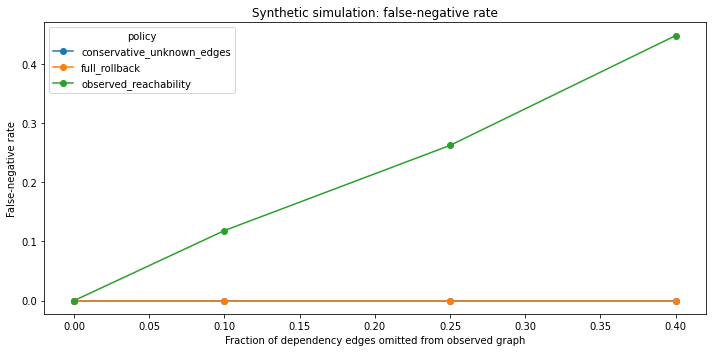

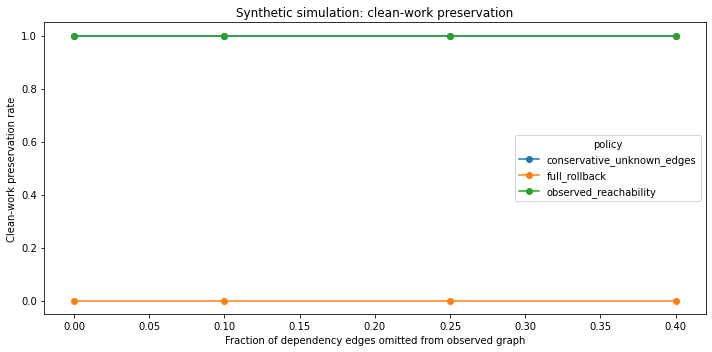

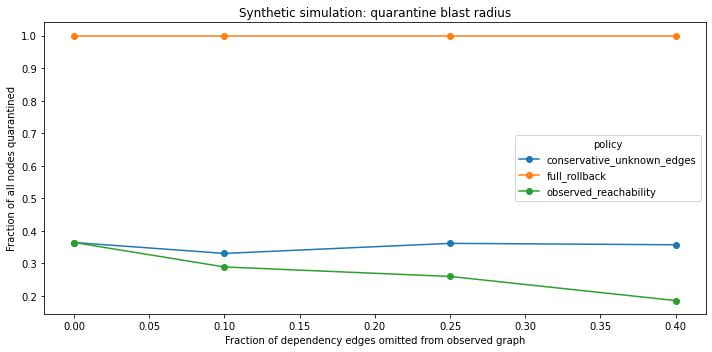

In [5]:
plot_metrics = [
    ("false_negative_rate", "Synthetic simulation: false-negative rate", "False-negative rate"),
    ("clean_work_preservation_rate", "Synthetic simulation: clean-work preservation", "Clean-work preservation rate"),
    ("quarantine_blast_radius", "Synthetic simulation: quarantine blast radius", "Fraction of all nodes quarantined")
]
for metric, title, ylabel in plot_metrics:
    pivot = trial_df.groupby(["missing_edge_rate", "policy"])[metric].mean().unstack("policy")
    ax = pivot.plot(marker="o", figsize=(10, 5))
    ax.set_title(title)
    ax.set_xlabel("Fraction of dependency edges omitted from observed graph")
    ax.set_ylabel(ylabel)
    plt.tight_layout()
    plt.show()

## 6. Assertions and measured synthetic findings

In [6]:
# Verify each trial-policy result is internally consistent.
assert (trial_df["ground_truth_contaminated"] + trial_df["ground_truth_clean"] == N_NODES).all()
assert (trial_df["false_negative_nodes"] <= trial_df["ground_truth_contaminated"]).all()
assert (trial_df["false_positive_nodes"] <= trial_df["ground_truth_clean"]).all()
assert (trial_df["clean_work_preserved"] + trial_df["false_positive_nodes"] == trial_df["ground_truth_clean"]).all()

# Report measured means from this run rather than hard-coding a superiority claim.
summary_for_report = trial_df.groupby(["missing_edge_rate", "policy"])[
    ["false_negative_rate", "false_positive_rate", "clean_work_preservation_rate", "quarantine_blast_radius"]
].mean().reset_index()
display(summary_for_report)

for rate in MISSING_EDGE_RATES:
    subset = summary_for_report[summary_for_report["missing_edge_rate"] == rate].set_index("policy")
    print(f"Missing-edge rate {rate:.0%}:")
    for policy in ["full_rollback", "observed_reachability", "conservative_unknown_edges"]:
        row = subset.loc[policy]
        print(f"  {policy}: FN={row['false_negative_rate']:.3f}, FP={row['false_positive_rate']:.3f}, "
              f"clean-preservation={row['clean_work_preservation_rate']:.3f}, "
              f"blast-radius={row['quarantine_blast_radius']:.3f}")

print("All Lab 04.01 assertions passed.")

    missing_edge_rate                      policy  false_negative_rate  false_positive_rate  clean_work_preservation_rate  quarantine_blast_radius
0                0.00  conservative_unknown_edges             0.000000                  0.0                           1.0                 0.364250
1                0.00               full_rollback             0.000000                  1.0                           0.0                 1.000000
2                0.00       observed_reachability             0.000000                  0.0                           1.0                 0.364250
3                0.10  conservative_unknown_edges             0.000000                  0.0                           1.0                 0.330750
4                0.10               full_rollback             0.000000                  1.0                           0.0                 1.000000
5                0.10       observed_reachability             0.118391                  0.0                           

Missing-edge rate 0%:
  full_rollback: FN=0.000, FP=1.000, clean-preservation=0.000, blast-radius=1.000
  observed_reachability: FN=0.000, FP=0.000, clean-preservation=1.000, blast-radius=0.364
  conservative_unknown_edges: FN=0.000, FP=0.000, clean-preservation=1.000, blast-radius=0.364
Missing-edge rate 10%:
  full_rollback: FN=0.000, FP=1.000, clean-preservation=0.000, blast-radius=1.000
  observed_reachability: FN=0.118, FP=0.000, clean-preservation=1.000, blast-radius=0.289
  conservative_unknown_edges: FN=0.000, FP=0.000, clean-preservation=1.000, blast-radius=0.331
Missing-edge rate 25%:
  full_rollback: FN=0.000, FP=1.000, clean-preservation=0.000, blast-radius=1.000
  observed_reachability: FN=0.262, FP=0.000, clean-preservation=1.000, blast-radius=0.260
  conservative_unknown_edges: FN=0.000, FP=0.000, clean-preservation=1.000, blast-radius=0.362
Missing-edge rate 40%:
  full_rollback: FN=0.000, FP=1.000, clean-preservation=0.000, blast-radius=1.000
  observed_reachability: F

## 7. Export reproducibility artifacts

In [7]:
trial_df.to_csv("trustsr_lab04_01_trial_level_results.csv", index=False)
node_df.to_csv("trustsr_lab04_01_node_level_classifications.csv", index=False)
aggregate_df.to_csv("trustsr_lab04_01_aggregate_metrics.csv", index=False)
summary_for_report.to_csv("trustsr_lab04_01_policy_summary.csv", index=False)

print("CSV exports created:")
for filename in [
    "trustsr_lab04_01_trial_level_results.csv",
    "trustsr_lab04_01_node_level_classifications.csv",
    "trustsr_lab04_01_aggregate_metrics.csv",
    "trustsr_lab04_01_policy_summary.csv"
]:
    print("-", filename)
print("Evidence classification: synthetic simulation only.")

CSV exports created:
- trustsr_lab04_01_trial_level_results.csv
- trustsr_lab04_01_node_level_classifications.csv
- trustsr_lab04_01_aggregate_metrics.csv
- trustsr_lab04_01_policy_summary.csv
Evidence classification: synthetic simulation only.


## 8. Interpretation, limitations, and reporting rules

### What this lab can establish
It can quantify, under the stated synthetic graph model, the trade-off between:
- missed contaminated nodes,
- clean nodes unnecessarily quarantined,
- preserved clean work,
- total quarantine blast radius.

It can also test whether the conservative policy's extra quarantine reduces false negatives in these generated scenarios. Use the printed means and CSVs; do not assume it is better in advance.

### Limitations
- The DAG, edge omissions, and contamination process are synthetic.
- An omitted edge is known to the evaluator because ground truth is available; a real system may not know which edges are missing.
- The conservative policy uses the simulator's missing-edge list directly, which is an oracle-like signal. This makes it an optimistic upper-bound policy, not a directly deployable algorithm.
- Full rollback is represented as quarantining all states; practical rollback semantics can differ.
- No actual agent, memory store, tool call, external side effect, or real incident was tested.
- Results depend on the chosen seed, graph-generation parameters, and policy definitions.

### Required wording for a paper
“Under a synthetic directed-acyclic dependency model, we compared full quarantine, observed-graph reachability, and a conservative policy given explicit missing-edge information. Reported metrics characterize this simulation only; they do not establish production effectiveness or security guarantees.”

### Next step after this lab
Review the executed PDF and CSVs. If the result is internally consistent, Lab 04.02 should replace oracle-known missing edges with realistic uncertainty signals and test calibration / abstention, rather than simply adding more synthetic complexity.